## Chordsense : DSP Analysis

This jupyter notebook is designed to study and analyze DSP analysis in Python.
Python is quite useful for its various libraries, we will use these libraries. It is also useful for plotting.

In [39]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
from dsp.sine import sine as sine
import dsp.fourier_transform as ft
import dsp.fft as fft

importlib.reload(ft)
dft = ft.dft
amplitude_spectrum = ft.amplitude_spectrum

We will now just generate a sine wave.

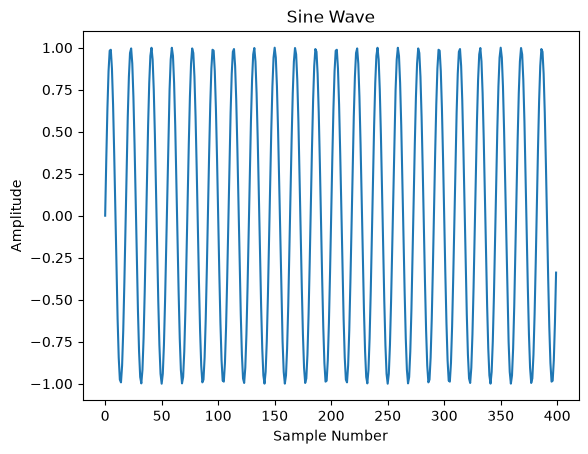

In [40]:
# Use matplotlib's interactive mode to generate a sine wave

sine_wave = sine(440, 0.05, 8000)  # Generate a sine wave with frequency 1 Hz, sample rate 0.01 s, and 1000 samples

plt.ion()  # Turn on interactive mode
plt.plot(sine_wave)  # Plot the sine wave
plt.title("Sine Wave")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.show()  # Display the plot

Now let's try the C chord.

C3 = 130.81 Hz
E3 = 164.81 Hz
G3 = 196.00 Hz

Let's sample this at 44100 Hz, take 44100 samples, so 1 second of recording.

First let's plot the C chord. We will use the numpy's sine function instead.

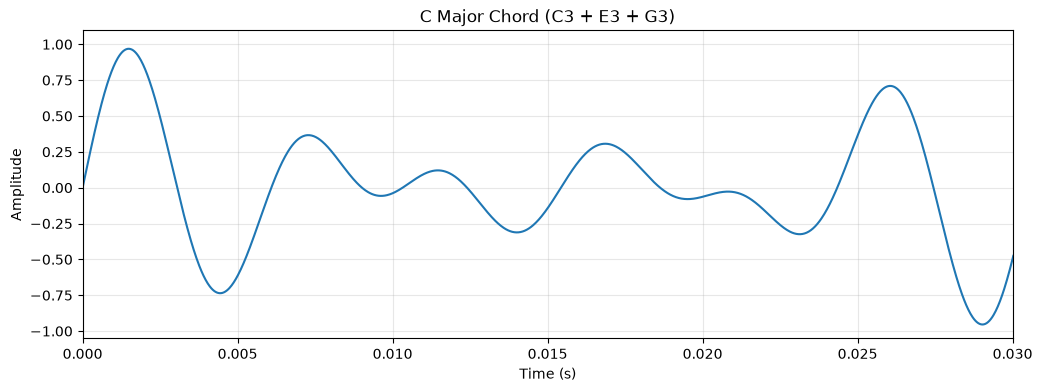

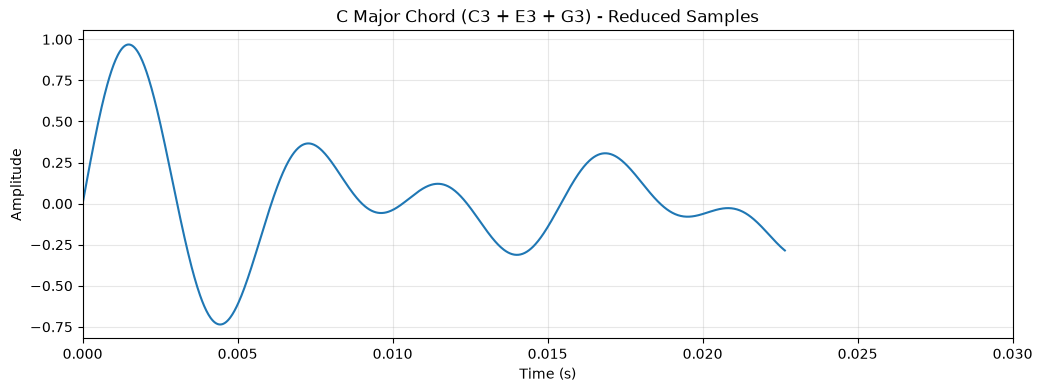

In [41]:
# C major chord: C3, E3, G3
fs = 44100
n_samples = 44100
n_reduced_samples = 1000  # Reduce to first 1000 samples for plotting

# Generate time vector, samples from 0 to 1 second
# Each time step is 1/fs, so t = [0, 1/fs, 2/fs, ..., (n_samples-1)/fs]
t = np.arange(n_samples) / fs
t_reduced = np.arange(n_reduced_samples) / fs  # Reduced time vector for plotting

# The 44100 sample case #

# Our notes: C3 (130.81 Hz), E3 (164.81 Hz), G3 (196.00 Hz)
c3 = np.sin(2 * np.pi * 130.81 * t)
e3 = np.sin(2 * np.pi * 164.81 * t)
g3 = np.sin(2 * np.pi * 196.00 * t)

# We normalize to avoid clipping when we sum the waves.
c_chord = (c3 + e3 + g3) / 3

# The reduced sample case for plotting

c_3_reduced = np.sin(2 * np.pi * 130.81 * t_reduced)
e_3_reduced = np.sin(2 * np.pi * 164.81 * t_reduced)
g_3_reduced = np.sin(2 * np.pi * 196.00 * t_reduced)
c_chord_reduced = (c_3_reduced + e_3_reduced + g_3_reduced) / 3

# Plot the C major chord waveform
plt.figure(figsize=(12, 4))
plt.plot(t, c_chord)
plt.title("C Major Chord (C3 + E3 + G3)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.03)  # zoom in to see waveform shape
plt.grid(True, alpha=0.3)
plt.show()

# Plot the reduced C major chord waveform
plt.figure(figsize=(12, 4))
plt.plot(t_reduced, c_chord_reduced)
plt.title("C Major Chord (C3 + E3 + G3) - Reduced Samples")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.03)  # zoom in to see waveform shape
plt.grid(True, alpha=0.3)
plt.show()

Next, let's proceed to create a frequency spectrum by performing the DFT. The code below works, but it will take a very long time to actually load the results with 44100 samples

The complexity time is O(n^2), that complexity time becomes very long when faced with 44100 samples.

Therefore we will only use 1000 samples for this example.

mean(c_chord_reduced) = 0.03903399948926757
N = 1000 delta_f = 44.1 Hz
target 130.81 Hz -> nearest bin 132.30 Hz, amplitude 0.310582
target 164.81 Hz -> nearest bin 176.40 Hz, amplitude 0.261145
target 196.00 Hz -> nearest bin 176.40 Hz, amplitude 0.261145


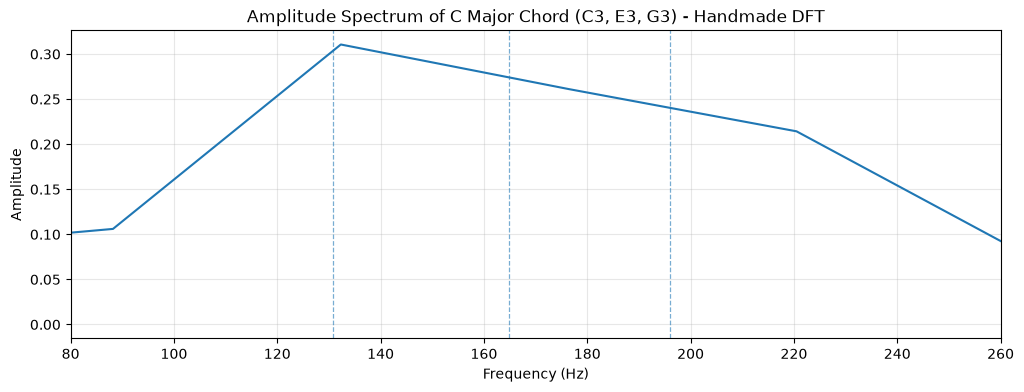

In [42]:
# there is probably a DC bias
print("mean(c_chord_reduced) =", np.mean(c_chord_reduced))

# Remove DC bias from the short window, then compute spectrum with handmade DFT
signal = c_chord_reduced - np.mean(c_chord_reduced)
complex_spectrum = dft(signal)
amps = amplitude_spectrum(complex_spectrum)

# Manual frequency axis for single-sided spectrum: f_k = k * fs / N
N = len(signal)
freqs = np.arange(N // 2 + 1) * fs / N

# Inspect where the three note frequencies land
targets = [130.81, 164.81, 196.00]

print('N =', N, 'delta_f =', fs / N, 'Hz')
for target in targets:
    idx = np.argmin(np.abs(freqs - target))
    print(f'target {target:.2f} Hz -> nearest bin {freqs[idx]:.2f} Hz, amplitude {amps[idx]:.6f}')

# Plot in Hz and zoom to the musical region
plt.figure(figsize=(12, 4))
plt.plot(freqs, amps)
for f in targets:
    plt.axvline(f, linestyle='--', linewidth=0.9, alpha=0.6)
plt.title('Amplitude Spectrum of C Major Chord (C3, E3, G3) - Handmade DFT')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.xlim(80, 260)
plt.grid(True, alpha=0.3)
plt.show()

To get the frequency spectrum of the C chord with 44100 samples, it is best to use the Fast Fourier Transform algorithm.

It works recursively, essentially diviving every odd and even element in the sample set, until it reaches the base case. We will use Python's np. equivalent.

original N = 44100 padded N = 65536 delta_f = 0.67291259765625 Hz
target 130.81 Hz -> nearest bin 130.55 Hz, amplitude 0.300280
target 164.81 Hz -> nearest bin 164.86 Hz, amplitude 0.333760
target 196.00 Hz -> nearest bin 195.82 Hz, amplitude 0.316092


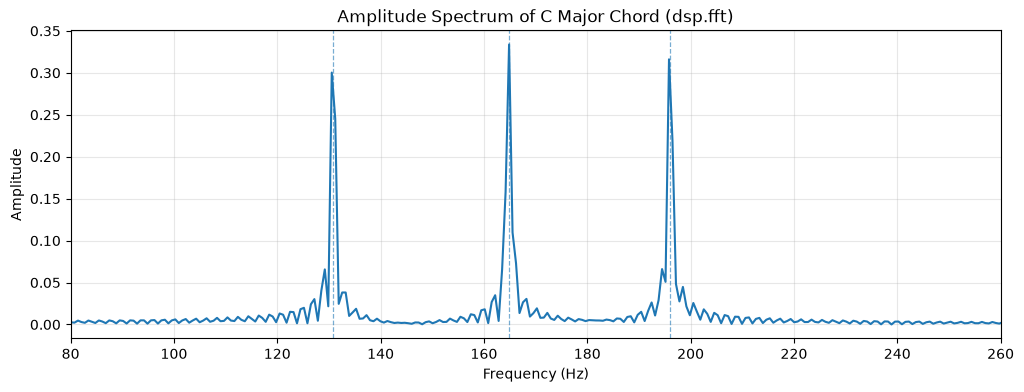

In [43]:
# Use FFT implementation from dsp.fft on the full C chord
signal_dsp = c_chord - np.mean(c_chord)  # remove DC bias
N_dsp = len(signal_dsp)

# dsp.fft needs power-of-two length, so pad with zeros
N_fft = 1 << (N_dsp - 1).bit_length()
signal_fft = np.zeros(N_fft)
signal_fft[:N_dsp] = signal_dsp

fft_complex_dsp = fft.fft(signal_fft)

# Scale by original (unpadded) sample count so amplitudes stay comparable
amps_dsp = (2.0 / N_dsp) * np.abs(fft_complex_dsp[: N_fft // 2 + 1])
amps_dsp[0] *= 0.5
freqs_dsp = np.arange(N_fft // 2 + 1) * fs / N_fft

print('original N =', N_dsp, 'padded N =', N_fft, 'delta_f =', fs / N_fft, 'Hz')
for f0 in targets:
    idx = np.argmin(np.abs(freqs_dsp - f0))
    print(f'target {f0:.2f} Hz -> nearest bin {freqs_dsp[idx]:.2f} Hz, amplitude {amps_dsp[idx]:.6f}')

# Plot the amplitude spectrum from dsp.fft
plt.figure(figsize=(12, 4))
plt.plot(freqs_dsp, amps_dsp)
for f0 in targets:
    plt.axvline(f0, linestyle='--', linewidth=0.9, alpha=0.6)
plt.title('Amplitude Spectrum of C Major Chord (dsp.fft)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.xlim(80, 260)
plt.grid(True, alpha=0.3)
plt.show()

In any case, this was just to explore the capabilities of FFT. 

From now on, we will use the numpy's fft version.

## Pipeline


In this section we take a look at the pipeline.

Before accessing the pipeline, it is important to first know about the use of harmonics. This is because they are very common in musical instruments, thus should be accounted for.

A harmonic is a frequency component of a complex periodic wave that is an exact integer multiple of the fundamental frequency. They shape the timbre as well, in other words, they are the reason why the sound of a guitar sounds like a guitar. 

Generally in DSP, you need to account for harmonics since they can cause aliasing. Harmonics can exceed the Nyquist frequency, thus it folds back around the frequency spectrum. Harmonics also add extra peaks, which the pipeline may read as extra notes.

Therefore, if you wanted to test the C major chord, you would expect 3 peaks, but actually get more than 3 due to harmonics



### Harmonic Example

As an example to figuring out harmonics, let's use the **C4** note, which is at **261.63 Hz**.

The **first** harmonic is 1x, thus the frequency remains at 261.63 Hz. This also referred to as the fundamental frequency.

The **second** harmonic is 2x, so it is the double of the fundamental frequency. It is at 523.25 Hz. The closest note to that frequency is C5. 

To convert any frequency ($f$ in Hz) to a musical note, we use the standard MIDI note formula:

$$\text{MIDI Note} = 69 + 12 \times \log_2\left(\frac{f}{440}\right)$$

#### Harmonic Interval Reference Table

| Harmonic | Multiplier ($r$) | Semitones Above Root ($12 \times \log_2 r$) | Musical Interval (from Root) |
| :--- | :--- | :--- | :--- |
| **1st** | $1$ | $0$ | Unison (Root Note) |
| **2nd** | $2$ | $+12$ | Octave |
| **3rd** | $3$ | $\approx +19.02$ | Octave + Perfect 5th |
| **4th** | $4$ | $+24$ | Two Octaves |
| **5th** | $5$ | $\approx +27.86$ | Two Octaves + Major 3rd |

Therefore, to complete the C major chord;

| Harmonic ($n$) | C Series (Root) | E Series (Third) | G Series (Fifth) | Notable Overlaps / Additions |
| :--- | :--- | :--- | :--- | :--- |
| **1st ($1f_0$)** | C4 | E4 | G4 | Fundamental Chord (C, E, G) |
| **2nd ($2f_0$)** | C5 | E5 | G5 | Octaves up |
| **3rd ($3f_0$)** | G5 | B5 | D6 | Fifths & Ninths |
| **4th ($4f_0$)** | C6 | E6 | G6 | Double Octaves |
| **5th ($5f_0$)** | E6 | **G#6** | B6 | **G#6 appears** (from E's 5th harmonic) |

The $harmonic\_note$ function takes any frequency, considers it as the fundamental frequencies, then creates it's harmonics. As a default, it returns an array-like of 5 harmonics. It also has the important capability of **damping**. 

**Damping** is very important in digital signal processing as it makes the less relevant harmonics have a smaller amplitude. Otherwise, all amplitudes, regardless of harmonic importance, are the same.

**Decay Rate** is also important because it governs how quickly different harmonics fade out over time—with higher frequencies dying out faster than the fundamental. This gives synthesized sounds a natural, acoustic evolution rather than a static, robotic tone.

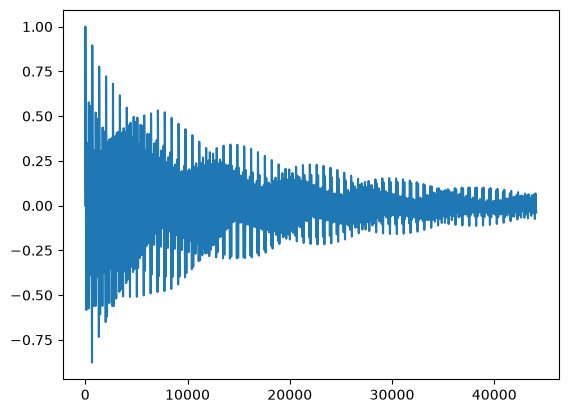

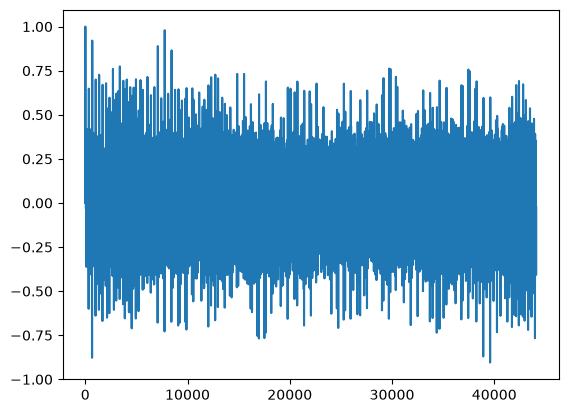

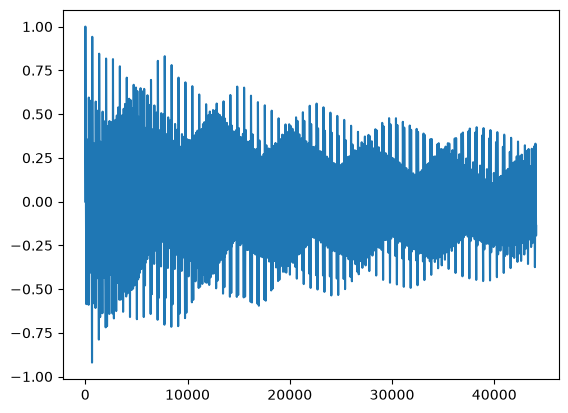

In [48]:
# Import the pipeline
from dsp.sine import harmonic_note

# Generate a DAMPED harmonic note, the C4 chord.
notes_damped_C = harmonic_note(261.63, 1, damped=True)
notes_damped_E = harmonic_note(329.63, 1, damped=True)
notes_damped_G = harmonic_note(392.00, 1, damped=True)

# Generate the undamped chord (same amplitudes for the C4 chord's harmonics)
notes_C = harmonic_note(261.63, 1)
notes_E = harmonic_note(329.63, 1)
notes_G = harmonic_note(392.00, 1)

# Next let's generate the damped c chord but with a shorter decay rate
notes_damped_short_C = harmonic_note(261.63, 1, damped=True, decay_rate=0.5)
notes_damped_short_E = harmonic_note(329.63, 1, damped=True, decay_rate=0.5)
notes_damped_short_G = harmonic_note(392.00, 1, damped=True, decay_rate=0.5)

# Normalize the chord
damped_chord = notes_damped_C + notes_damped_E + notes_damped_G
chord = notes_C + notes_E + notes_G
damped_short_chord = notes_damped_short_C + notes_damped_short_E + notes_damped_short_G

# Normalize the chords
damped_normalized_chord = damped_chord / max(abs(damped_chord))
chord = chord / max(abs(chord))
damped_short_chord = damped_short_chord / max(abs(damped_short_chord))

# Show the damped chord
plt.plot(damped_normalized_chord)
plt.show()

# Show the undamped chord
plt.plot(chord)
plt.show()

# Show the short damped chord
plt.plot(damped_short_chord)
plt.show()

Now, let's try to run our pipeline with damped and undamped chords.

By performing this test, we can quickly see that harmonics need to be damped and set a proper decay rate, otherwise our pipeline fails at detecting chords.

This is an important factor for synthesized signals. However, as mentioned before, harmonics naturally are produced by instruments, thus our DSP pipeline will be able to decypher the frequencies anyways. 

In [50]:
from pipeline.chord_guess import prepare_frame, signal_to_peaks, guess_chord
from dsp.note_tools import frequency_to_note

def detect_chord(signal):

    # Prepare the frame for analysis
    frame, weights = prepare_frame(signal, frame_size=44100)

    # Find the peaks and the notable frequencies
    peaks = signal_to_peaks(frame, 44100, window_weights=weights)

    # Print each peak's info
    for p in sorted(peaks, key=lambda p: p["frequency_hz"]):

        # Convert to note info
        info = frequency_to_note(p["frequency_hz"])
        print(
            f"{p['frequency_hz']:.2f} Hz",
            info["note"],
            f"{info['cents']:+.2f} cents",
            f"amplitude={p['amplitude']:.4f}",
        )

    # Number of peaks
    print("Peak count:", len(peaks))
    # Guess the chord
    print("Chord:", guess_chord(peaks))

# Example usage

print("Detecting the DAMPED C chord")
detect_chord(damped_normalized_chord)
print("\nDetecting the C chord")
detect_chord(chord)
print("\nDetecting the short damped C chord")
detect_chord(damped_short_chord)

Detecting the DAMPED C chord
262.00 Hz C4 +2.48 cents amplitude=0.0779
330.00 Hz E4 +1.96 cents amplitude=0.0779
392.00 Hz G4 +0.02 cents amplitude=0.0850
523.00 Hz C5 -0.83 cents amplitude=0.0182
659.00 Hz E5 -0.67 cents amplitude=0.0182
784.00 Hz G5 +0.02 cents amplitude=0.0187
Peak count: 6
Chord: C

Detecting the C chord
262.00 Hz C4 +2.48 cents amplitude=0.0792
330.00 Hz E4 +1.96 cents amplitude=0.0792
392.00 Hz G4 +0.02 cents amplitude=0.0866
523.00 Hz C5 -0.83 cents amplitude=0.0829
659.00 Hz E5 -0.67 cents amplitude=0.0829
785.00 Hz G5 +2.23 cents amplitude=0.0475
989.00 Hz B5 +2.16 cents amplitude=0.0860
1047.00 Hz C6 +0.82 cents amplitude=0.0745
1176.00 Hz D6 +1.98 cents amplitude=0.0866
1308.00 Hz E6 -13.86 cents amplitude=0.0854
1319.00 Hz E6 +0.64 cents amplitude=0.0745
1568.00 Hz G6 +0.02 cents amplitude=0.0866
1648.00 Hz G#6 -13.83 cents amplitude=0.0854
1960.00 Hz B6 -13.67 cents amplitude=0.0866
Peak count: 14
Chord: None

Detecting the short damped C chord
262.00 Hz C